In [24]:
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns 

import tensorflow as tf
from tensorflow.keras import layers, regularizers


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score

In [25]:
# import data from local file as a dataframe

df = pd.read_excel("Telco_customer_churn.xlsx")

In [26]:
# Finding information about the dataset
print(df.head(5))
print(df.info())
print(df.describe())
print(df.isna().sum())
print(df.isna().mean())

   CustomerID  Count        Country       State         City  Zip Code  \
0  3668-QPYBK      1  United States  California  Los Angeles     90003   
1  9237-HQITU      1  United States  California  Los Angeles     90005   
2  9305-CDSKC      1  United States  California  Los Angeles     90006   
3  7892-POOKP      1  United States  California  Los Angeles     90010   
4  0280-XJGEX      1  United States  California  Los Angeles     90015   

                 Lat Long   Latitude   Longitude  Gender  ...        Contract  \
0  33.964131, -118.272783  33.964131 -118.272783    Male  ...  Month-to-month   
1   34.059281, -118.30742  34.059281 -118.307420  Female  ...  Month-to-month   
2  34.048013, -118.293953  34.048013 -118.293953  Female  ...  Month-to-month   
3  34.062125, -118.315709  34.062125 -118.315709  Female  ...  Month-to-month   
4  34.039224, -118.266293  34.039224 -118.266293    Male  ...  Month-to-month   

  Paperless Billing             Payment Method  Monthly Charges Tota

In [27]:
for col in df.select_dtypes("object"):
    print(col, df[col].unique())


df = df.drop(columns=["Churn Label"])

CustomerID <ArrowStringArray>
['3668-QPYBK', '9237-HQITU', '9305-CDSKC', '7892-POOKP', '0280-XJGEX',
 '4190-MFLUW', '8779-QRDMV', '1066-JKSGK', '6467-CHFZW', '8665-UTDHZ',
 ...
 '0871-OPBXW', '3605-JISKB', '9767-FFLEM', '8456-QDAVC', '7750-EYXWZ',
 '2569-WGERO', '6840-RESVB', '2234-XADUH', '4801-JZAZL', '3186-AJIEK']
Length: 7043, dtype: str
Country <ArrowStringArray>
['United States']
Length: 1, dtype: str
State <ArrowStringArray>
['California']
Length: 1, dtype: str
City <ArrowStringArray>
[    'Los Angeles',   'Beverly Hills', 'Huntington Park',         'Lynwood',
  'Marina Del Rey',       'Inglewood',    'Santa Monica',        'Torrance',
        'Whittier',        'La Habra',
 ...
      'Janesville',      'Litchfield',        'Loyalton',        'Madeline',
    'Markleeville',         'Milford',         'Calpine',        'Standish',
        'Tulelake',  'Olympic Valley']
Length: 1129, dtype: str
Lat Long <ArrowStringArray>
['33.964131, -118.272783',  '34.059281, -118.30742', '34.04

C:\Users\riley\AppData\Local\Temp\ipykernel_37060\542491838.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object"):


In [28]:
# Replacing empty strings with NaN values and converting "Total Charges" to numeric
df = df.replace(r"^\s*$", pd.NA, regex=True)
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
print(df["Total Charges"].isna().sum())
print(df.info())

11
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null

In [29]:
print(df["CustomerID"].duplicated().sum())

0


In [30]:
# Filling NaN values in "Total Charges" with 0 for customers with 0 tenure months
df.loc[df["Tenure Months"] == 0, "Total Charges"] = 0
print(df["Total Charges"].isna().sum())

0


In [31]:
#saving churn score as a benchmark for later use
churn_score = df["Churn Score"]
churn_reason = df["Churn Reason"]

In [32]:
# Dropping unnecessary columns from the dataframe
df.drop(columns=["Churn Score", "Churn Reason", "CustomerID", "Lat Long", "Country", "State", "Count", "CLTV"], inplace=True)


print(df.isna().sum().sum())

0


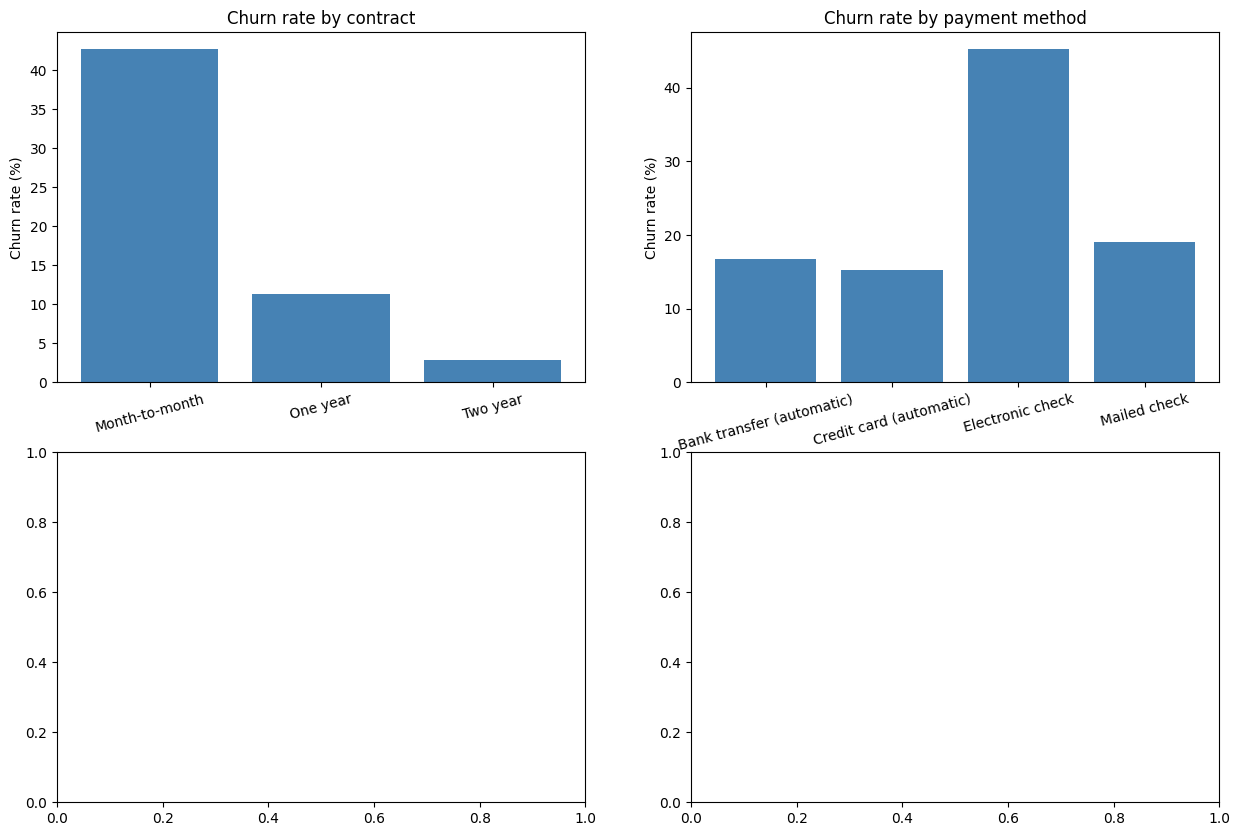

In [33]:
plot_df = df.assign(churn=df["Churn Value"].map({0:"stayed",1:"churned"}))

fig,axes = plt.subplots(2,2,figsize=(15,10))

contract_rate=df.groupby("Contract")["Churn Value"].mean()*100

contract_rate = df.groupby("Contract")["Churn Value"].mean() * 100
axes[0, 0].bar(contract_rate.index, contract_rate.values, color="steelblue")
axes[0, 0].set_title("Churn rate by contract")
axes[0, 0].set_ylabel("Churn rate (%)")
axes[0, 0].tick_params(axis="x", rotation=15)

payment_rate = df.groupby("Payment Method")["Churn Value"].mean() * 100
axes[0,1].bar(payment_rate.index,payment_rate.values,color="steelblue")
axes[0,1].set_title("Churn rate by payment method")
axes[0,1].set_ylabel("Churn rate (%)")
axes[0,1].tick_params(axis="x", rotation=15)


In [34]:
target = "Churn Value"

x = df.drop(columns=[target,"Churn Reason"],errors = "ignore")
y = df[target].astype("int32")


X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42,stratify=y)

print("Training inputs:", X_train.shape)
print("Test inputs:", X_test.shape)
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTest target proportions:")
print(y_test.value_counts(normalize=True).round(3))

print("Text/category columns:")
print(X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist())

print("\nNumeric columns:")
print(X_train.select_dtypes(include="number").columns.tolist())

Training inputs: (5634, 23)
Test inputs: (1409, 23)

Training target proportions:
Churn Value
0    0.735
1    0.265
Name: proportion, dtype: float64

Test target proportions:
Churn Value
0    0.735
1    0.265
Name: proportion, dtype: float64
Text/category columns:
['City', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']

Numeric columns:
['Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges']


In [35]:
location_columns = ["City", "Zip Code", "Lat Long", "Country", "State"]

X_train_ready = X_train.drop(columns=location_columns, errors="ignore")
X_test_ready = X_test.drop(columns=location_columns, errors="ignore")

X_train_ready = pd.get_dummies(X_train_ready, dtype="float32")
X_test_ready = pd.get_dummies(X_test_ready, dtype="float32")

X_test_ready = X_test_ready.reindex(columns=X_train_ready.columns, fill_value=0)


print("training data shape:", X_train_ready.shape)
print("test data shape:", X_test_ready.shape)
print("any non numeric columns in training data?", X_train_ready.select_dtypes(exclude="number").columns.tolist())

training data shape: (5634, 48)
test data shape: (1409, 48)
any non numeric columns in training data? []


In [36]:
from sklearn.preprocessing import StandardScaler

scale_colums = ["Tenure Months", "Monthly Charges", "Total Charges"]
scaler = StandardScaler()

X_train_ready[scale_colums] = scaler.fit_transform(X_train_ready[scale_colums])

X_test_ready[scale_colums] = scaler.transform(X_test_ready[scale_colums])

print("Training inputs:", X_train_ready.shape)
print("Test inputs:", X_test_ready.shape)
print("\nScaled training feature averages:")
print(X_train_ready[scale_colums].mean().round(2))

Training inputs: (5634, 48)
Test inputs: (1409, 48)

Scaled training feature averages:
Tenure Months     -0.0
Monthly Charges   -0.0
Total Charges      0.0
dtype: float64


In [37]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_fit_smote,y_fit_smote = smote.fit_resample(X_fit,y_fit)

print("Before SMOTE:", y_fit.value_counts().to_dict())
print("After SMOTE:", y_fit_smote.value_counts().to_dict())

gb_smote = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=30,
    random_state=42
)

gb_smote.fit(X_fit_smote,y_fit_smote)

smote_val_probabilities = gb_smote.predict_proba(X_val)[:,1]

candidates = []

for threshold in np.arange(0.05,0.96,0.01):
    val_predictions = (smote_val_probabilities >= threshold).astype(int)

    precision = precision_score(y_val,val_predictions,zero_division=0)
    recall = recall_score(y_val,val_predictions,zero_division=0)

    if recall >= 0.70:
        candidates.append((threshold,precision,recall))

if candidates:
    best_threshold,best_precision,best_recall = max(candidates,key=lambda result: result[1])

    

    print(f"threshhold: {best_threshold:.2f}, precision: {best_precision:.3f}, recall: {best_recall:.3f}")

else:
    print("No threshold found that meets the recall requirement.")

Before SMOTE: {0: 3311, 1: 1196}
After SMOTE: {0: 3311, 1: 3311}
threshhold: 0.46, precision: 0.605, recall: 0.716


In [38]:
%pip install streamlit


   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   ---------------------------------- ----- 9.4/11.0 MB 45.2 MB/s eta 0:00:01
   ---------------------------------------- 11.0/11.0 MB 42.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 2.6/2.6 MB 37.0 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.34.1
    Uninstalling protobuf-7.34.1:
      Successfully uninstalled protobuf-7.34.1
  Attempting uninstall: pillow
    Found existing installation: pillow 12.2.0
    Uninstalling pillow-12.2.0:
      Successfully uninstalled pillow-12.2.0
  Attempting uninstall: packaging
    Found existing installation: packaging 26.1
    Uninstalling packaging-26.1:
      Successfully uninstalled packaging-26.1
  Attempting uninstall: rich
    Found existing installation: rich 15.0.0
    Uninstalling rich-15.0.0:
      Successfully uninstalled rich-15.0.0
 

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
rembg 2.0.75 requires pillow<13.0.0,>=12.1.0, but you have pillow 10.4.0 which is incompatible.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.
tensorflow 2.21.0 requires protobuf<8.0.0,>=6.31.1, but you have protobuf 5.29.6 which is incompatible.
